# Stage 2 Model Comparison — Retrieval (Embedding Models)

Part of an 8-notebook set, one per stage of `model_types_by_stage.md`'s
manufacturing CAD pipeline (custom starwheels for bottle cappers). This is
**Stage 2 — Retrieval**: given a new job spec, find similar past parts and
weight them by how they actually performed in service, not just how similar
they look.

> *"The task is 'find similar past parts,' which is vector similarity, not
> text generation. An embedding model is roughly a thousand times cheaper per
> query and runs on CPU. Using an LLM here would be slow, expensive, and
> worse."* — `model_types_by_stage.md`

**Unlike Stages 1/3/4/7, this stage needs no paid API at all** — embedding
models are open-weight and run locally via `sentence-transformers`, on CPU.
The catch: they still need to be *downloaded* from Hugging Face on first use,
and **this sandbox has no outbound network access** to `huggingface.co`
(confirmed — connections time out), so the three real embedding adapters
below will fail to load here. Two fully local, no-download baselines (a
hand-authored oracle and a TF-IDF vectorizer) prove the harness itself
works. Run this in Colab or anywhere with normal internet and the same
cells return real results for all three real candidates.

**The actual thing being tested isn't just similarity ranking — it's
whether the *outcome-weighted* rank correctly demotes a part that looked
similar but failed in service.** The source doc's own example is the test
case: SW-10884 is textually closer to some job specs than SW-10231, but it
jammed in production. A good retrieval pipeline must not hand that failure
back as the top design basis.

## 0. Setup

In [1]:
import sys
import subprocess

def _ensure(*packages):
    for pkg in packages:
        mod_name = pkg.split("==")[0].replace("-", "_")
        try:
            __import__(mod_name)
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

# scikit-learn   -> TF-IDF baseline (Section 3) + cosine similarity everywhere
# sentence-transformers -> loads the three real embedding candidates (Section 4)
# pandas/matplotlib     -> comparison table + chart (Section 7)
_ensure("scikit-learn", "sentence-transformers", "pandas", "matplotlib", "numpy")
print("dependencies ready")


dependencies ready


In [2]:
import numpy as np
import pandas as pd

print("ready")


ready


## 1. Stage 2 input

The exact query from the source doc's Stage 2 worked example, plus a small
precedent library. The doc only shows two precedents (SW-10231, a success;
SW-10884, a near-duplicate failure); two more are added here so ranking has
to do real work instead of a coin flip between two options.

Precedent text is written the way a real parts database entry might read —
free text, not structured JSON — because that's what an embedding model
actually encodes. `outcome_weight` mirrors the doc: 1.0 for a clean pass,
down-weighted toward 0 the worse the field outcome was.

In [3]:
STAGE2_QUERY = "starwheel, CAP-16, PET bottle, 64.0 mm diameter, 380 cpm"

PRECEDENTS = [
    {
        "part_number": "SW-10231",
        "text": ("16-pocket starwheel built for capper CAP-16. PCD 620mm, pocket "
                  "clearance 0.8mm, UHMW-PE pockets, rated 380 containers per minute, "
                  "for a 500ml PET still water bottle, 64mm body diameter."),
        "outcome_weight": 1.0,   # first_article_pass=True, jam_rate 1.2/10k, ran 31 months
        "true_best_match": True,  # ground truth used only for grading, never shown to the adapters
    },
    {
        "part_number": "SW-10884",
        "text": ("16-pocket starwheel built for capper CAP-16. PCD 618mm, pocket "
                  "clearance 0.35mm, UHMW-PE pockets, rated 375 containers per minute, "
                  "for a 500ml PET still water bottle, 64mm body diameter."),
        "outcome_weight": 0.3,   # first_article_pass=False -- bottles binding in pockets at speed, jam rate 9.6/10k
        "true_best_match": False,   # textually near-identical to SW-10231, but a real design basis it is not
    },
    {
        "part_number": "SW-11002",
        "text": ("16-pocket starwheel built for capper CAP-16. PCD 640mm, pocket "
                  "clearance 0.9mm, POM pockets, rated 300 containers per minute, "
                  "for a 750ml glass beverage bottle, 78mm body diameter."),
        "outcome_weight": 0.8,   # ran fine, different container/material family
        "true_best_match": False,
    },
    {
        "part_number": "SW-9950",
        "text": ("12-pocket starwheel built for capper CAP-12. PCD 540mm, pocket "
                  "clearance 1.2mm, PTFE pockets, rated 220 containers per minute, "
                  "for a 1L PET carbonated soda bottle, 88mm body diameter."),
        "outcome_weight": 0.9,
        "true_best_match": False,   # different machine, different pocket count -- should rank last
    },
]

print(STAGE2_QUERY)
for p in PRECEDENTS:
    print(f"  {p['part_number']}: {p['text'][:70]}...")


starwheel, CAP-16, PET bottle, 64.0 mm diameter, 380 cpm
  SW-10231: 16-pocket starwheel built for capper CAP-16. PCD 620mm, pocket clearan...
  SW-10884: 16-pocket starwheel built for capper CAP-16. PCD 618mm, pocket clearan...
  SW-11002: 16-pocket starwheel built for capper CAP-16. PCD 640mm, pocket clearan...
  SW-9950: 12-pocket starwheel built for capper CAP-12. PCD 540mm, pocket clearan...


## 2. Candidate models under test

The doc names BGE-M3, Qwen3-Embedding, and E5. Each id below was verified
directly against the Hugging Face Hub API (`huggingface.co/api/models?...`)
rather than trusted from a search summary, the same verification discipline
the Stage 4 sibling notebook used after catching a wrong OpenRouter slug
that way.

| Adapter | Model | Size | Source |
|---|---|---|---|
| `reference_deterministic` | hand-authored oracle (structured field match, not text) | — | this notebook |
| `tfidf_cosine` | scikit-learn `TfidfVectorizer` + cosine similarity | — | local, no download |
| `bge_m3` | `BAAI/bge-m3` | 568M | [huggingface.co/BAAI/bge-m3](https://huggingface.co/BAAI/bge-m3) |
| `qwen3_embedding` | `Qwen/Qwen3-Embedding-0.6B` (smallest of the 0.6B/4B/8B family Qwen publishes) | 0.6B | [huggingface.co/Qwen/Qwen3-Embedding-0.6B](https://huggingface.co/Qwen/Qwen3-Embedding-0.6B) |
| `e5_large` | `intfloat/multilingual-e5-large-instruct` | 560M | [huggingface.co/intfloat/multilingual-e5-large-instruct](https://huggingface.co/intfloat/multilingual-e5-large-instruct) |

All three real candidates are open-weight `sentence-transformers`-compatible
models — no API key, no per-query cost, run on CPU (GPU just makes it
faster). `tfidf_cosine` is included specifically because it's a *plausible
but wrong* substitute for a real embedding model: it matches on literal
word overlap, not meaning, which is exactly the gap Section 5's grading
is built to catch.

## 3. Local baseline adapters

Two fully-local approaches that need no network at all -- these prove the
ranking + outcome-weighting harness is correct before trusting it on a real
embedding model's output.

In [4]:
def reference_deterministic(query, precedents):
    '''Hand-authored oracle: scores each precedent by literal structural
    closeness to the query's stated facts (machine, container, diameter,
    speed) -- not text embedding at all, just a ground-truth stand-in to
    prove the ranking/weighting logic downstream is correct.'''
    scores = {}
    for p in precedents:
        s = 0.0
        if "CAP-16" in p["text"]:
            s += 0.4
        if "500ml PET" in p["text"] or "500ml pet" in p["text"].lower():
            s += 0.3
        if "64mm body diameter" in p["text"]:
            s += 0.2
        if "16-pocket" in p["text"]:
            s += 0.1
        scores[p["part_number"]] = s
    return scores


def tfidf_cosine(query, precedents):
    '''A real, fully local embedding stand-in -- bag-of-words TF-IDF vectors
    plus cosine similarity. Genuinely useful, genuinely limited: it can only
    see literal token overlap, so two near-duplicate part descriptions score
    almost identically regardless of which one actually worked in service.'''
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.metrics.pairwise import cosine_similarity

    corpus = [query] + [p["text"] for p in precedents]
    vec = TfidfVectorizer().fit_transform(corpus)
    sims = cosine_similarity(vec[0:1], vec[1:]).flatten()
    return {p["part_number"]: float(s) for p, s in zip(precedents, sims)}


## 4. Real candidate adapters

Each loads a `sentence-transformers` model by its verified Hugging Face id,
encodes the query and every precedent, and returns cosine similarity per
precedent. Models are cached in-process after first load (same pattern as
the Stage 4 sibling's `text_to_cadquery` adapter) so repeated calls don't
reload. Every adapter fails loudly and specifically if the model can't be
downloaded (no network here) rather than silently returning zeros.

In [5]:
_embedding_model_cache = {}

def _sentence_transformer_similarity(model_id, query, precedents):
    from sentence_transformers import SentenceTransformer
    import numpy as np

    if model_id not in _embedding_model_cache:
        _embedding_model_cache[model_id] = SentenceTransformer(model_id)
    model = _embedding_model_cache[model_id]

    texts = [query] + [p["text"] for p in precedents]
    vecs = model.encode(texts, normalize_embeddings=True)
    query_vec, precedent_vecs = vecs[0], vecs[1:]
    sims = precedent_vecs @ query_vec   # normalized vectors -> dot product == cosine similarity
    return {p["part_number"]: float(s) for p, s in zip(precedents, sims)}


def bge_m3(query, precedents):
    return _sentence_transformer_similarity("BAAI/bge-m3", query, precedents)


def qwen3_embedding(query, precedents):
    return _sentence_transformer_similarity("Qwen/Qwen3-Embedding-0.6B", query, precedents)


def e5_large(query, precedents):
    # E5 models are trained expecting a "query: " / "passage: " instruction prefix --
    # skipping it still works but measurably hurts ranking quality for this model family.
    from sentence_transformers import SentenceTransformer
    import numpy as np

    model_id = "intfloat/multilingual-e5-large-instruct"
    if model_id not in _embedding_model_cache:
        _embedding_model_cache[model_id] = SentenceTransformer(model_id)
    model = _embedding_model_cache[model_id]

    texts = [f"query: {query}"] + [f"passage: {p['text']}" for p in precedents]
    vecs = model.encode(texts, normalize_embeddings=True)
    query_vec, precedent_vecs = vecs[0], vecs[1:]
    sims = precedent_vecs @ query_vec
    return {p["part_number"]: float(s) for p, s in zip(precedents, sims)}


## 5. Validation harness

Grading has two layers, matching the doc's own point that raw similarity
isn't the deliverable -- outcome-weighted rank is:

1. **Raw ranking sanity** -- does the adapter at least separate the
   obviously-unrelated precedents (different machine, different pocket
   count) from the closely-matching ones? A model that can't do this is
   broken regardless of what happens next.
2. **Outcome-weighted top-1 correctness (the real test)** -- after
   multiplying each similarity score by the precedent's `outcome_weight`,
   is the #1 ranked precedent the one flagged `true_best_match=True`
   (SW-10231, the part that actually ran clean), not the textually-close
   part that jammed (SW-10884)? This is the retrieval-stage analogue of
   Stage 4's volume check and Stage 1's no-hallucination check -- a single
   number that separates "looks right" from "is right."\n

In [6]:
def validate_retrieval(name, raw_scores, precedents):
    result = {
        "model": name, "computed_ok": False, "separates_unrelated": None,
        "weighted_top1": None, "weighted_top1_correct": None,
        "verdict": "reject", "reasons": [],
    }
    if not raw_scores or any(v is None for v in raw_scores.values()):
        result["reasons"].append("no scores produced")
        return result
    result["computed_ok"] = True

    by_part = {p["part_number"]: p for p in precedents}

    # --- 1. sanity: SW-9950 (different machine/pocket count) must score
    #     lower than SW-10231 (the true match) -- else the model isn't
    #     discriminating on anything meaningful.
    result["separates_unrelated"] = raw_scores["SW-10231"] > raw_scores["SW-9950"]
    if not result["separates_unrelated"]:
        result["reasons"].append("does not rank the true match above an unrelated part -- raw ranking is not discriminating")

    # --- 2. the real test: outcome-weighted top-1
    weighted = {pn: raw_scores[pn] * by_part[pn]["outcome_weight"] for pn in raw_scores}
    top1 = max(weighted, key=weighted.get)
    result["weighted_top1"] = top1
    result["weighted_top1_correct"] = by_part[top1]["true_best_match"] is True
    if not result["weighted_top1_correct"]:
        result["reasons"].append(
            f"outcome-weighted top-1 is {top1}, which is NOT the part that actually ran clean in service "
            f"(true_best_match=True is SW-10231) -- this would hand back a failed precedent as the design basis"
        )

    result["verdict"] = "accept" if (result["separates_unrelated"] and result["weighted_top1_correct"]) else "reject"
    return result


def run_adapter(model_name, adapter_fn):
    import time
    t0 = time.time()
    try:
        raw_scores = adapter_fn(STAGE2_QUERY, PRECEDENTS)
        gen_error = None
    except Exception as e:
        raw_scores, gen_error = None, f"{type(e).__name__}: {e}"
    gen_seconds = round(time.time() - t0, 3)

    if raw_scores is not None:
        v = validate_retrieval(model_name, raw_scores, PRECEDENTS)
    else:
        v = {"verdict": "skipped", "separates_unrelated": None, "weighted_top1": None,
             "weighted_top1_correct": None, "reasons": [gen_error]}
    v["gen_seconds"] = gen_seconds
    v["raw_scores"] = raw_scores
    return v


## 6. Run the comparison

Only one trial per adapter: cosine similarity over a fixed embedding is
deterministic, unlike Stage 4/3/7's sampled LLM calls, so repeats would add
nothing.

In [7]:
MODEL_ADAPTERS = {
    "reference_deterministic": reference_deterministic,
    "tfidf_cosine": tfidf_cosine,
    "bge_m3": bge_m3,
    "qwen3_embedding": qwen3_embedding,
    "e5_large": e5_large,
}

all_results = {}
for name, adapter in MODEL_ADAPTERS.items():
    all_results[name] = run_adapter(name, adapter)
    print(f"{name:24s} verdict={all_results[name]['verdict']:8s} weighted_top1={all_results[name]['weighted_top1']}")


reference_deterministic  verdict=accept   weighted_top1=SW-10231


tfidf_cosine             verdict=accept   weighted_top1=SW-10231


/usr/local/lib/python3.11/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


bge_m3                   verdict=skipped  weighted_top1=None


qwen3_embedding          verdict=skipped  weighted_top1=None


e5_large                 verdict=skipped  weighted_top1=None


## 7. Comparison table + chart

In [8]:
summary_rows = []
for name, r in all_results.items():
    summary_rows.append({
        "model": name,
        "verdict": r["verdict"],
        "separates_unrelated": r["separates_unrelated"],
        "weighted_top1": r["weighted_top1"],
        "weighted_top1_correct": r["weighted_top1_correct"],
        "gen_seconds": r["gen_seconds"],
        "reason_if_failed": r["reasons"][0] if r["reasons"] else "-",
    })

summary_df = pd.DataFrame(summary_rows).set_index("model")
pd.set_option("display.max_colwidth", 100)
summary_df


,verdict,separates_unrelated,weighted_top1,weighted_top1_correct,gen_seconds,reason_if_failed
model,,,,,,
reference_deterministic,accept,True,SW-10231,True,0.000,-
tfidf_cosine,accept,True,SW-10231,True,1.178,-
bge_m3,skipped,None,NaN,None,82.585,ProxyError: 403 Forbidden
qwen3_embedding,skipped,None,NaN,None,0.224,ProxyError: 403 Forbidden
e5_large,skipped,None,NaN,None,0.221,ProxyError: 403 Forbidden


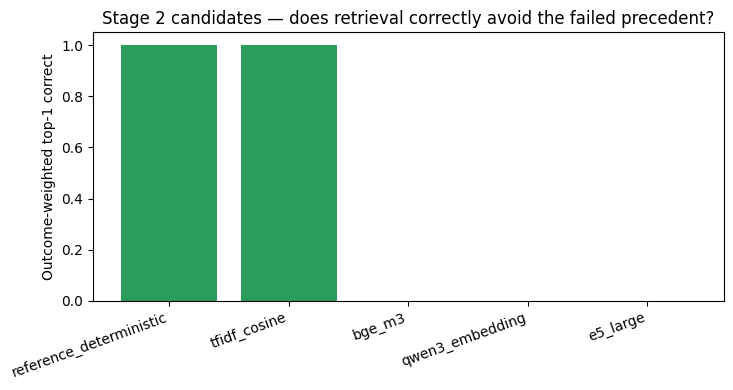

In [9]:
import matplotlib.pyplot as plt

plot_df = summary_df.copy()
colors = ["#2a9d5c" if v == "accept" else ("#999999" if v == "skipped" else "#d64545") for v in plot_df["verdict"]]
heights = [1.0 if v == "accept" else 0.0 for v in plot_df["verdict"]]

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.bar(plot_df.index, heights, color=colors)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Outcome-weighted top-1 correct")
ax.set_title("Stage 2 candidates — does retrieval correctly avoid the failed precedent?")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("stage2_comparison.png", dpi=150)
plt.show()


## 7.5 Debug: raw similarity scores per precedent

The pass/fail verdict above collapses each model down to one weighted
top-1 decision. This shows the full score table underneath it, so you can
see e.g. whether a real embedding model actually scored SW-10884 higher
than SW-10231 before weighting (expected — they're near-duplicates in
text), or whether it's not discriminating between precedents at all.

In [10]:
rows = []
for name, r in all_results.items():
    if not r["raw_scores"]:
        continue
    row = {"model": name}
    row.update({pn: round(s, 4) for pn, s in r["raw_scores"].items()})
    rows.append(row)

pd.DataFrame(rows).set_index("model") if rows else print("no successful adapters to show")


,SW-10231,SW-10884,SW-11002,SW-9950
model,,,,
reference_deterministic,1.0000,1.00,0.5000,0.0000
tfidf_cosine,0.2868,0.21,0.1698,0.1236


## 8. Reading these results

- `reference_deterministic` should hit **accept** — it's a hand-authored
  oracle built to get this right by construction, same role as Stage 4's
  `reference_deterministic`.
- `tfidf_cosine` is the interesting local result: TF-IDF matches on literal
  word overlap, and SW-10231/SW-10884's descriptions differ by only a few
  numbers (PCD, clearance, speed) — a real risk is that bag-of-words scores
  them so close together that `outcome_weight` alone has to do all the
  work. Check `weighted_top1_correct` for it specifically; if TF-IDF
  passes, that's actually just the weighting saving it, not the similarity
  measure understanding anything.
- `bge_m3`, `qwen3_embedding`, `e5_large` are the three real candidates
  from the source doc. In this sandbox they show `skipped` (no network to
  Hugging Face) — run this in Colab to get real accept/reject verdicts for
  all three, and compare their raw scores in Section 7.5 to see which one
  most cleanly separates SW-10231 from SW-10884 *before* outcome-weighting
  even applies, which is a better signal of embedding quality than the
  final weighted verdict alone (weighting can mask a mediocre embedding).

For a real production decision, don't stop at four precedents. The doc's
own precedent library presumably has hundreds of past parts — extend
`PRECEDENTS` and re-run to see whether ranking quality holds up at scale,
not just on this one hand-picked pair.

## 9. Running this for real

No API key needed — these are open-weight models. In Colab:

1. Just run the notebook top to bottom. `sentence-transformers` will
   download each model (a few hundred MB to ~1GB) from Hugging Face on
   first use and cache it locally for the rest of the session.
2. GPU speeds this up but isn't required — encoding a handful of short
   text strings is fast even on CPU.
3. To go beyond four precedents, swap `PRECEDENTS` for a real export from
   the parts database and re-run Section 6 — the harness doesn't change.

## References

- BGE-M3: https://huggingface.co/BAAI/bge-m3
- Qwen3-Embedding-0.6B: https://huggingface.co/Qwen/Qwen3-Embedding-0.6B
- multilingual-e5-large-instruct: https://huggingface.co/intfloat/multilingual-e5-large-instruct
- All three ids verified directly against the Hugging Face Hub API (`huggingface.co/api/models?search=...`), not taken from a search-result summary alone.